In [1]:
# doing logistic regression using gradient descent

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.datasets import make_classification

In [4]:
X, y = make_classification(n_samples= 100, n_classes= 2, n_clusters_per_class= 1, n_features= 2, n_informative= 1, n_redundant= 0, n_repeated= 0, class_sep= 5)

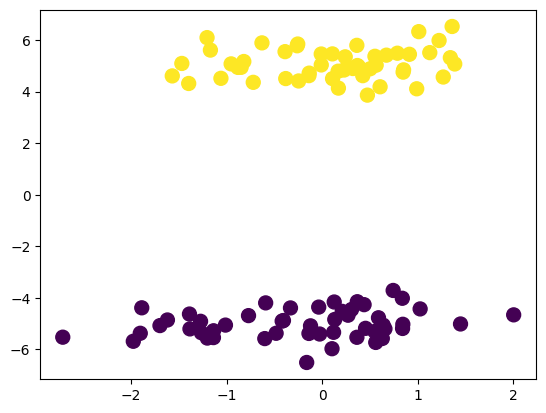

In [5]:
plt.scatter(X[:, 0], X[:, 1], c = y, s= 100)

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [8]:
# using buildin logistic class

In [9]:
from sklearn.linear_model import LogisticRegression

In [10]:
lg = LogisticRegression(penalty= None, solver= 'sag')

In [11]:
lg.fit(X_train, y_train)

C:\Users\gpava\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,penalty,None
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'sag'
,max_iter,100
,multi_class,'deprecated'


In [12]:
lg.coef_

array([[-0.19779878,  2.15203205]])

In [13]:
m = -(lg.coef_[0][0]/ lg.coef_[0][1])
b = -(lg.intercept_ / lg.coef_[0][1])

In [14]:
x_input = np.linspace(-3, 3, 100)
y_input = m * x_input + b

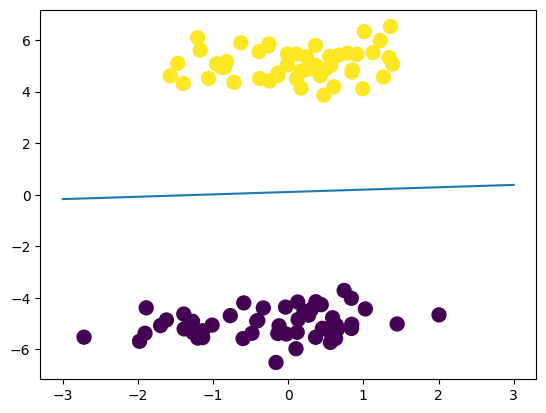

In [15]:
plt.scatter(X[:, 0], X[:, 1], c = y, s = 100)
plt.plot(x_input, y_input)

In [16]:
# now using our own class 

In [25]:
class Logistic_gradient:

    def __init__(self, lr, epochs):
        self.lr = lr
        self.epochs = epochs
        self.coefs = None

    def sigmoid(self, X):
        return np.round(1 / (1 + np.exp(-X)), 2)

    def fit(self, X_train, y_train):
        X_train = np.insert(X_train, 0, 1, axis= 1)
        self.coefs = np.ones(X_train.shape[1])
        for i in range(self.epochs):
            Y_hat = self.sigmoid(np.dot(X_train, self.coefs))
            self.coefs = self.coefs + self.lr * ((np.dot(y_train - Y_hat, X_train)) / (X_train.shape[0]))

In [46]:
lg2 = Logistic_gradient(0.01, 10000)

In [47]:
lg2.fit(X_train, y_train)

In [48]:
lg2.coefs

array([0.870015  , 0.87940363, 1.61074989])

In [49]:
m = -(lg2.coefs[1]/ lg2.coefs[2])
b = -(lg2.coefs[0] / lg2.coefs[2])

In [50]:
x_input_2 = np.linspace(-3, 3, 100)
y_input_2 = m * x_input_2 + b

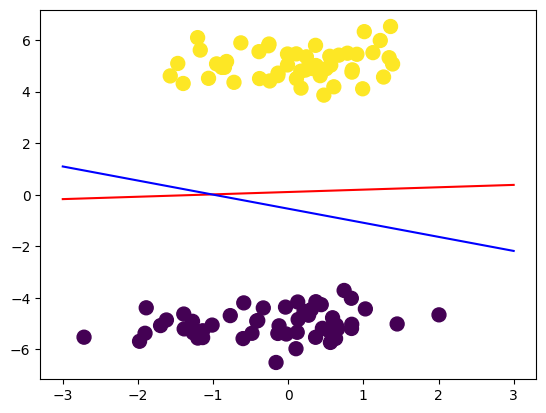

In [51]:
plt.scatter(X[:, 0], X[:, 1], c = y, s = 100)
plt.plot(x_input, y_input, color = 'red')
plt.plot(x_input_2, y_input_2, color = 'blue')